In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [22]:
data = pd.read_csv("./exam_scores.csv")
x = data["Hours"].values
y_actual = data["Score"].values


def compute_cost(x, y, w, b):
    m = len(x)
    y_predicted = w * x + b
    cost = np.sum((y_predicted - y) ** 2) / (2 * m)
    return cost



w = 0
b = 0
j = compute_cost(x, y_actual, w, b)
print("Initial Cost J:", j)

Initial Cost J: 2153.7894736842104


In [23]:
import numpy as np

# Ensure inputs are NumPy arrays for safe integer indexing
x = data['Hours'].values
y_actual = data['Score'].values
m = len(data)

def compute_gradient(x, y_actual, m, w, b):
    dj_dw = 0.0
    dj_db = 0.0

    for i in range(m):
        prediction = w * x[i] + b
        error = prediction - y_actual[i]

        dj_dw += error * x[i]
        dj_db += error

    dj_dw /= m
    dj_db /= m

    return dj_dw, dj_db


# Lowered learning rate to prevent exploding to NaN
learning_rate = 0.001  

# Tighter convergence threshold
tolerance = 1e-5  

w = 0.0
b = 0.0
cnt = 0

while cnt < 1000:
    dj_dw, dj_db = compute_gradient(x, y_actual, m, w, b)

    temp_w = w - learning_rate * dj_dw
    temp_b = b - learning_rate * dj_db

    # Safety check: stop if values explode
    if np.isnan(temp_w) or np.isnan(temp_b):
        print(f"Diverged at iteration {cnt}! Try lowering the learning rate.")
        break

    # Convergence check
    if abs(temp_w - w) < tolerance and abs(temp_b - b) < tolerance:
        print(f"Converged at iteration {cnt}")
        break

    w = temp_w
    b = temp_b
    cnt += 1

print(f"Final parameters: w = {w:.4f}, b = {b:.4f}")

Final parameters: w = 10.3010, b = 2.5375


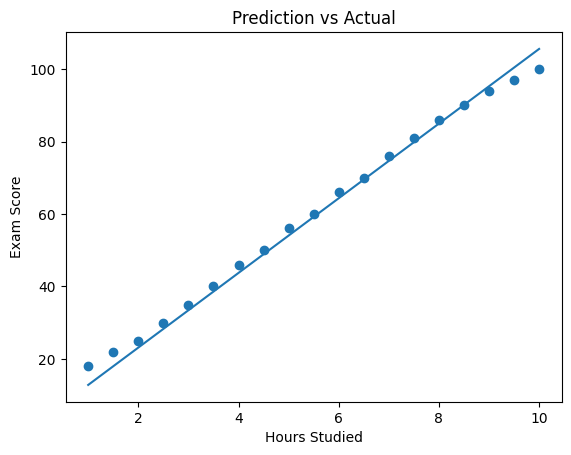

In [25]:
# lets make the graph using these parameters
y_now=w*x+b
plt.scatter(x, y_actual)

plt.plot(x, y_now)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Prediction vs Actual")

plt.show()
    